In [5]:
import pandas as pd

ASSISTANT_TYPE = "diabetes"

data = diabetes_data if ASSISTANT_TYPE == "diabetes" else heart_data

df = pd.DataFrame(data, columns=["query", "intent"])

print("Total queries:", len(df))
print(df["intent"].value_counts())

Total queries: 40
intent
symptoms       8
blood_sugar    8
diet           8
exercise       8
medication     4
prevention     4
Name: count, dtype: int64


In [1]:
!pip install -q nltk scikit-learn

In [8]:
import nltk
import re
import pandas as pd

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [6]:
ASSISTANT_TYPE = "diabetes"

diabetes_data = [
("diabetes symptoms", "symptoms"),
("signs of diabetes", "symptoms"),
("high sugar symptoms", "symptoms"),
("diabetes fatigue", "symptoms"),
("diabetes thirst", "symptoms"),
("frequent urination", "symptoms"),
("blurred vision diabetes", "symptoms"),
("diabetes warning signs", "symptoms"),

("normal blood sugar", "blood_sugar"),
("control blood sugar", "blood_sugar"),
("high blood sugar", "blood_sugar"),
("low blood sugar", "blood_sugar"),
("check blood glucose", "blood_sugar"),
("fasting blood sugar", "blood_sugar"),
("what is HbA1c", "blood_sugar"),
("blood glucose level", "blood_sugar"),

("diabetes diet", "diet"),
("foods for diabetes", "diet"),
("foods to avoid", "diet"),
("diabetes and fruits", "diet"),
("diabetes breakfast", "diet"),
("diabetes vegetables", "diet"),
("diabetes and sweets", "diet"),
("healthy diabetic food", "diet"),

("diabetes exercise", "exercise"),
("walking and diabetes", "exercise"),
("exercise for diabetes", "exercise"),
("gym with diabetes", "exercise"),
("exercise and blood sugar", "exercise"),
("safe diabetes exercise", "exercise"),
("exercise and insulin", "exercise"),
("exercise low sugar", "exercise"),

("diabetes medicine", "medication"),
("insulin use", "medication"),
("metformin use", "medication"),
("diabetes treatment", "medication"),
("prevent diabetes", "prevention"),
("diabetes risk", "prevention"),
("type 1 diabetes", "prevention"),
("type 2 diabetes", "prevention")
]

heart_data = [
("heart disease symptoms", "symptoms"),
("heart attack signs", "symptoms"),
("chest discomfort", "symptoms"),
("heart shortness of breath", "symptoms"),
("heart palpitations", "symptoms"),
("heart dizziness", "symptoms"),
("heart warning signs", "symptoms"),
("heart fatigue", "symptoms"),

("normal blood pressure", "blood_pressure"),
("high blood pressure", "blood_pressure"),
("lower blood pressure", "blood_pressure"),
("blood pressure check", "blood_pressure"),
("what is hypertension", "blood_pressure"),
("stress blood pressure", "blood_pressure"),
("low blood pressure", "blood_pressure"),
("blood pressure importance", "blood_pressure"),

("heart healthy foods", "diet"),
("foods for heart", "diet"),
("salt and heart", "diet"),
("fish and heart", "diet"),
("vegetables and heart", "diet"),
("saturated fat", "diet"),
("heart healthy diet", "diet"),
("oatmeal and heart", "diet"),

("heart exercise", "exercise"),
("walking for heart", "exercise"),
("heart strengthening exercise", "exercise"),
("exercise hypertension", "exercise"),
("exercise cholesterol", "exercise"),
("heart physical activity", "exercise"),
("exercise heart health", "exercise"),
("heart disease prevention exercise", "exercise"),

("prevent heart disease", "prevention"),
("heart disease risk", "prevention"),
("smoking and heart", "prevention"),
("obesity and heart", "prevention"),
("heart medicines", "medication"),
("statins use", "medication"),
("blood thinners", "medication"),
("heart disease prevention", "prevention")
]

data = diabetes_data if ASSISTANT_TYPE == "diabetes" else heart_data

df = pd.DataFrame(data, columns=["query", "intent"])

print("Total queries:", len(df))
print(df["intent"].value_counts())

Total queries: 40
intent
symptoms       8
blood_sugar    8
diet           8
exercise       8
medication     4
prevention     4
Name: count, dtype: int64


In [9]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = text.split()
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]
    return " ".join(tokens)

df["processed_query"] = df["query"].apply(preprocess)

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [12]:
X = df["processed_query"]
y = df["intent"]

vectorizer = TfidfVectorizer()

X_tfidf = vectorizer.fit_transform(X)

print("TF-IDF shape:", X_tfidf.shape)

TF-IDF shape: (40, 42)


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = MultinomialNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.625
              precision    recall  f1-score   support

 blood_sugar       1.00      1.00      1.00         2
        diet       0.25      1.00      0.40         1
    exercise       1.00      0.50      0.67         2
  medication       0.00      0.00      0.00         1
  prevention       0.00      0.00      0.00         1
    symptoms       1.00      1.00      1.00         1

    accuracy                           0.62         8
   macro avg       0.54      0.58      0.51         8
weighted avg       0.66      0.62      0.59         8



In [16]:
taxonomy = {
    "Health Information": [
        "Symptoms",
        "Warning Signs"
    ],
    "Lifestyle": [
        "Diet",
        "Exercise"
    ],
    "Clinical Management": [
        "Medication",
        "Monitoring"
    ],
    "Prevention": [
        "Risk Factors",
        "Preventive Care"
    ]
}

for major, subcategories in taxonomy.items():
    print(major)
    for sub in subcategories:
        print("   └──", sub)

Health Information
   └── Symptoms
   └── Warning Signs
Lifestyle
   └── Diet
   └── Exercise
Clinical Management
   └── Medication
   └── Monitoring
Prevention
   └── Risk Factors
   └── Preventive Care


In [17]:
concepts = [
    "Blood Sugar",
    "Insulin",
    "Glucose",
    "Diet",
    "Exercise",
    "Medication",
    "Symptoms",
    "Risk Factors",
    "Blood Pressure",
    "Cholesterol"
]

relationships = [
    ("Insulin", "regulates", "Blood Sugar"),
    ("Diet", "affects", "Blood Sugar"),
    ("Exercise", "reduces", "Blood Sugar"),
    ("Medication", "controls", "Blood Sugar"),
    ("Glucose", "measured_by", "Blood Sugar"),
    ("High Blood Sugar", "causes", "Symptoms"),
    ("Risk Factors", "increase", "Disease Risk"),
    ("Exercise", "improves", "Heart Health"),
    ("Diet", "improves", "Heart Health"),
    ("Medication", "controls", "Blood Pressure"),
    ("Diet", "affects", "Cholesterol"),
    ("Exercise", "reduces", "Cholesterol")
]

print("CONCEPTS")
for c in concepts:
    print(c)

print("\nRELATIONSHIPS")
for r in relationships:
    print(r[0], "--", r[1], "-->", r[2])

CONCEPTS
Blood Sugar
Insulin
Glucose
Diet
Exercise
Medication
Symptoms
Risk Factors
Blood Pressure
Cholesterol

RELATIONSHIPS
Insulin -- regulates --> Blood Sugar
Diet -- affects --> Blood Sugar
Exercise -- reduces --> Blood Sugar
Medication -- controls --> Blood Sugar
Glucose -- measured_by --> Blood Sugar
High Blood Sugar -- causes --> Symptoms
Risk Factors -- increase --> Disease Risk
Exercise -- improves --> Heart Health
Diet -- improves --> Heart Health
Medication -- controls --> Blood Pressure
Diet -- affects --> Cholesterol
Exercise -- reduces --> Cholesterol


In [18]:
if ASSISTANT_TYPE == "diabetes":

    knowledge_base = {
        "symptoms": "Common diabetes symptoms include increased thirst, frequent urination, fatigue and blurred vision.",
        "blood_sugar": "Blood glucose monitoring helps track blood sugar. HbA1c provides an estimate of average blood glucose over several months.",
        "diet": "A balanced diet containing vegetables, whole grains, lean proteins and appropriate portions can support diabetes management.",
        "exercise": "Regular physical activity such as walking can help improve blood glucose control and insulin sensitivity.",
        "medication": "Diabetes medicines may include metformin, other glucose-lowering medicines or insulin depending on the person's condition.",
        "prevention": "Healthy eating, regular physical activity, maintaining a healthy weight and regular medical checkups can reduce the risk of type 2 diabetes."
    }

else:

    knowledge_base = {
        "symptoms": "Heart-related warning signs may include chest discomfort, shortness of breath, unusual fatigue, dizziness and palpitations.",
        "blood_pressure": "Blood pressure is an important indicator of cardiovascular health. Regular monitoring can help identify hypertension.",
        "diet": "A heart-healthy diet generally emphasizes vegetables, fruits, whole grains, fish and limiting excess sodium and saturated fats.",
        "exercise": "Regular physical activity such as walking can improve cardiovascular fitness and help manage several heart disease risk factors.",
        "prevention": "Not smoking, exercising regularly, eating a balanced diet and managing blood pressure and cholesterol can reduce cardiovascular risk.",
        "medication": "Medicines for cardiovascular conditions depend on the diagnosis and may include drugs for blood pressure or cholesterol."
    }

In [19]:
def healthcare_assistant(user_query):

    processed = preprocess(user_query)
    query_vector = vectorizer.transform([processed])

    predicted_intent = model.predict(query_vector)[0]

    probabilities = model.predict_proba(query_vector)[0]
    confidence = max(probabilities)

    response = knowledge_base.get(
        predicted_intent,
        "I could not find relevant information."
    )

    print("\nHealthcare Cognitive Assistant")
    print("User Query:", user_query)
    print("Detected Intent:", predicted_intent)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("\nResponse:")
    print(response)
    print("\nDisclaimer: This assistant provides general health information and is not a substitute for professional medical advice.")

In [20]:
healthcare_assistant("What foods should I eat?")


Healthcare Cognitive Assistant
User Query: What foods should I eat?
Detected Intent: diet
Confidence: 39.6 %

Response:
A balanced diet containing vegetables, whole grains, lean proteins and appropriate portions can support diabetes management.

Disclaimer: This assistant provides general health information and is not a substitute for professional medical advice.


In [22]:
print("HEALTHCARE COGNITIVE ASSISTANT")
print("Type 'exit' to stop.\n")

while True:

    user_input = input("You: ")

    if user_input.lower() == "exit":
        print("Assistant: Goodbye! Stay healthy.")
        break

    healthcare_assistant(user_input)

HEALTHCARE COGNITIVE ASSISTANT
Type 'exit' to stop.

You: 22

Healthcare Cognitive Assistant
User Query: 22
Detected Intent: diet
Confidence: 21.88 %

Response:
A balanced diet containing vegetables, whole grains, lean proteins and appropriate portions can support diabetes management.

Disclaimer: This assistant provides general health information and is not a substitute for professional medical advice.
You: exit
Assistant: Goodbye! Stay healthy.


Accuracy: 0.625

Classification Report:
              precision    recall  f1-score   support

 blood_sugar       1.00      1.00      1.00         2
        diet       0.25      1.00      0.40         1
    exercise       1.00      0.50      0.67         2
  medication       0.00      0.00      0.00         1
  prevention       0.00      0.00      0.00         1
    symptoms       1.00      1.00      1.00         1

    accuracy                           0.62         8
   macro avg       0.54      0.58      0.51         8
weighted avg       0.66      0.62      0.59         8



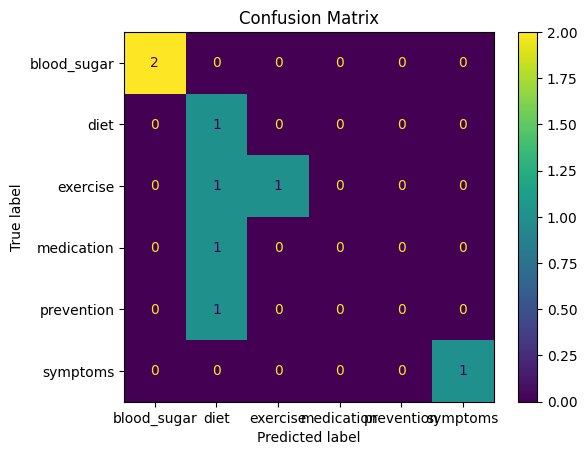

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [24]:
if ASSISTANT_TYPE == "diabetes":

    knowledge_base = {
        "symptoms": "Common symptoms include increased thirst, frequent urination, fatigue and blurred vision.",
        "blood_sugar": "Blood glucose monitoring helps track sugar levels. HbA1c measures average blood glucose over time.",
        "diet": "A balanced diet with vegetables, whole grains, lean proteins and controlled portions can support diabetes management.",
        "exercise": "Regular physical activity such as walking can help improve blood glucose control.",
        "medication": "Diabetes treatment may include medicines such as metformin or insulin depending on the individual's condition.",
        "prevention": "Healthy eating, regular exercise and maintaining a healthy weight can reduce the risk of type 2 diabetes."
    }

else:

    knowledge_base = {
        "symptoms": "Heart warning signs may include chest discomfort, shortness of breath, fatigue, dizziness and palpitations.",
        "blood_pressure": "Blood pressure monitoring is important for cardiovascular health and detecting hypertension.",
        "diet": "A heart-healthy diet includes vegetables, fruits, whole grains and fish while limiting excess salt and saturated fat.",
        "exercise": "Regular physical activity such as walking can improve cardiovascular fitness.",
        "prevention": "Avoiding smoking, exercising regularly and managing blood pressure and cholesterol can reduce heart disease risk.",
        "medication": "Heart-related medicines depend on the condition and may include medicines for blood pressure or cholesterol."
    }

print("Knowledge Base Created")

Knowledge Base Created


In [25]:
emergency_words = [
    "heart attack",
    "severe chest pain",
    "difficulty breathing",
    "fainting",
    "unconscious",
    "severe bleeding"
]

def check_emergency(query):
    query = query.lower()
    return any(word in query for word in emergency_words)


def check_supported(query):

    if ASSISTANT_TYPE == "diabetes":
        keywords = [
            "diabetes", "sugar", "glucose", "insulin",
            "food", "diet", "exercise", "blood", "metformin"
        ]
    else:
        keywords = [
            "heart", "blood pressure", "cholesterol",
            "chest", "exercise", "diet", "cardiac"
        ]

    return any(word in query.lower() for word in keywords)


def healthcare_assistant(query):

    if query.lower() == "exit":
        return "Goodbye! Stay healthy."

    if check_emergency(query):
        return "This may be an emergency. Please seek immediate medical attention or contact your local emergency service."

    if not check_supported(query):
        return "Sorry, I can only answer questions related to this healthcare domain."

    processed = preprocess(query)
    vector = vectorizer.transform([processed])

    probabilities = model.predict_proba(vector)[0]
    confidence = max(probabilities)

    if confidence < 0.35:
        return "I am not confident enough to answer this question. Please consult a healthcare professional."

    intent = model.predict(vector)[0]

    return knowledge_base.get(
        intent,
        "I could not find relevant information for your question."
    )

In [26]:
def ask_assistant(query):

    processed = preprocess(query)

    if check_emergency(query):
        print("Assistant: This may be an emergency. Please seek immediate medical attention.")
        return

    if not check_supported(query):
        print("Assistant: Sorry, I only answer questions related to this healthcare domain.")
        return

    vector = vectorizer.transform([processed])

    probabilities = model.predict_proba(vector)[0]
    confidence = max(probabilities)

    if confidence < 0.35:
        print("Assistant: I am not confident enough to answer this question.")
        return

    intent = model.predict(vector)[0]

    response = knowledge_base.get(
        intent,
        "Information not available."
    )

    print("Intent:", intent)
    print("Confidence:", round(confidence * 100, 2), "%")
    print("Assistant:", response)

In [27]:
print("========================================")
print("     HEALTHCARE COGNITIVE ASSISTANT")
print("========================================")
print("Type 'exit' to stop.\n")

while True:

    query = input("You: ")

    if query.lower() == "exit":
        print("Assistant: Goodbye! Stay healthy.")
        break

    ask_assistant(query)

     HEALTHCARE COGNITIVE ASSISTANT
Type 'exit' to stop.

You: what is the weather today?
Assistant: Sorry, I only answer questions related to this healthcare domain.
You: what are symptoms of diabetes?
Intent: symptoms
Confidence: 36.07 %
Assistant: Common symptoms include increased thirst, frequent urination, fatigue and blurred vision.
You: exit
Assistant: Goodbye! Stay healthy.
